## 1. Installer les bibliothèques
PyTorch sert aux tenseurs et aux batchs ; Datasets charge le corpus ; pandas et matplotlib permettent de l'inspecter. La préparation fonctionne sur CPU. Internet est nécessaire pour l'installation et le téléchargement initial.


In [1]:
%pip install -q "datasets>=3,<5" "torch>=2,<3" "pandas>=2,<3" "matplotlib>=3.8,<4"


## 2. Imports, réglages et dossiers
`PROJECT_DIR` est le dossier de sortie.

Le vocabulaire contient au maximum 10 000 tokens par langue, tokens spéciaux inclus ; cela limite le coût du décodeur. Aucun texte n'est tronqué pour préserver l'analyse des phrases longues.

En mode `local`, les fichiers JSONL doivent contenir une paire par ligne : `{"fr": "Bonjour.", "en": "Hello."}`.


In [3]:
import json
import re
import random
import unicodedata
import hashlib
import shutil
import platform
import importlib.metadata
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from datasets import load_dataset

PROJECT_DIR = Path("nlp_translation")
DATA_DIR = PROJECT_DIR / "data" / "prepared"
SRC_DIR = PROJECT_DIR / "src"
DATA_DIR.mkdir(parents=True, exist_ok=True)
SRC_DIR.mkdir(parents=True, exist_ok=True)

DATA_MODE = "huggingface"
LOCAL_DATA_DIR = Path("corpus_professeur")

CONFIG = {
    "seed": 42,
    "dataset": "Helsinki-NLP/opus-100",
    "dataset_config": "en-fr",
    "direction": "fr-en",
    "train_size": 30000,
    "validation_size": 2000,
    "test_size": 2000,
    "lowercase": True,
    "tokenizer": "unicode_regex_words_numbers_punctuation_v1",
    "max_vocab_size": 10000,
    "min_frequency": 2,
    "max_source_tokens": None,
    "max_target_tokens": None,
    "embedding_dim": 128,
    "hidden_dim": 256,
    "num_layers": 1,
    "batch_size": 64,
    "learning_rate": 0.001,
    "optimizer": "Adam",
    "teacher_forcing_ratio": 0.5,
    "epochs": 5,
    "checkpoint_selection": "lowest_validation_token_loss",
    "decoding": "greedy",
    "special_tokens": {"<PAD>": 0, "<UNK>": 1, "<SOS>": 2, "<EOS>": 3},
}
PAD_ID, UNK_ID, SOS_ID, EOS_ID = 0, 1, 2, 3
random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CONFIG["seed"])
print("GPU disponible :", torch.cuda.is_available())
print("Sorties :", PROJECT_DIR.resolve())


GPU disponible : False
Sorties : /content/nlp_translation


## 3. Nettoyer et tokeniser
On normalise Unicode, retire les espaces superflus, harmonise les apostrophes et passe en minuscules. Le motif conserve les accents, les mots avec apostrophe, les nombres et la ponctuation. C'est une tokenisation simple par mots, pas une tokenisation BPE.
Ces fonctions devront également être utilisées dans l'application.


In [4]:
TOKEN_PATTERN = re.compile(r"[^\W\d_]+(?:'[^\W\d_]+)*|\d+|[^\w\s]", flags=re.UNICODE)

def clean_text(text, lowercase=True):
    if not isinstance(text, str):
        raise TypeError("Une phrase doit être une chaîne de caractères.")
    text = unicodedata.normalize("NFKC", text)
    text = text.replace("’", "'")
    text = " ".join(text.split())
    return text.lower() if lowercase else text

def tokenize(text, lowercase=True):
    return TOKEN_PATTERN.findall(clean_text(text, lowercase=lowercase))

def prepare_pair(fr, en, lowercase=True):
    fr_clean = clean_text(fr, lowercase)
    en_clean = clean_text(en, lowercase)
    return {
        "fr_original": fr,
        "en_original": en,
        "fr": fr_clean,
        "en": en_clean,
        "src_tokens": tokenize(fr_clean, lowercase),
        "tgt_tokens": tokenize(en_clean, lowercase),
    }

def pair_key(row):
    return (tuple(row["src_tokens"]), tuple(row["tgt_tokens"]))


In [5]:
example = prepare_pair("  Je suis étudiante.  ", "I am a student.", CONFIG["lowercase"])
print("Français :", example["fr"])
print("Tokens FR :", example["src_tokens"])
print("Tokens EN :", example["tgt_tokens"])
assert tokenize("L’étudiante aime l'IA.") == ["l'étudiante", "aime", "l'ia", "."]


Français : je suis étudiante.
Tokens FR : ['je', 'suis', 'étudiante', '.']
Tokens EN : ['i', 'am', 'a', 'student', '.']


## 4. Charger le corpus
Le nom de configuration est `en-fr`, mais la source reste le français et la cible l'anglais : les clés `fr` / `en` définissent la direction.



In [6]:
def read_jsonl(path):
    with Path(path).open("r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

if DATA_MODE == "huggingface":
    raw = load_dataset(CONFIG["dataset"], CONFIG["dataset_config"])
    print(raw)
    print("Exemple brut :", raw["train"][0]["translation"])
elif DATA_MODE == "local":
    raw = {name: read_jsonl(LOCAL_DATA_DIR / f"{name}.jsonl")
           for name in ["train", "validation", "test"]}
    print({name: len(rows) for name, rows in raw.items()})
else:
    raise ValueError("DATA_MODE doit être 'huggingface' ou 'local'.")


README.md:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

en-fr/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  327kB            

en-fr/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en-fr/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  142MB            

en-fr/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

en-fr/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/1000000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['translation'],
        num_rows: 2000
    })
    train: Dataset({
        features: ['translation'],
        num_rows: 1000000
    })
    validation: Dataset({
        features: ['translation'],
        num_rows: 2000
    })
})
Exemple brut : {'en': 'The time now is 05:08 .', 'fr': 'The time now is 05:05 .'}


## 5. Fixer les ensembles et contrôler les recouvrements
En mode Hugging Face : conserver les deux ensembles officiels de 2 000 lignes ; mélanger l'entraînement avec la seed puis sélectionner 30 000 paires non vides et distinctes, sans paire présente dans la validation ou le test.

Les doublons internes et les recouvrements validation/test sont signalés, sans modifier ces ensembles à votre insu. Le contrôle porte sur les paires tokenisées exactes ; il ne détecte pas tous les quasi-doublons. En mode local, un recouvrement train/évaluation bloque l'exécution pour permettre d'en discuter avec l'enseignant.


In [7]:
def convert_row(row):
    translation = row.get("translation", row)
    return prepare_pair(translation["fr"], translation["en"], CONFIG["lowercase"])

def fixed_evaluation_split(name):
    expected = CONFIG[f"{name}_size"]
    if len(raw[name]) != expected:
        raise ValueError(f"{name} : {len(raw[name])} lignes au lieu de {expected}. "
                         "Vérifier la version commune du corpus.")
    rows = [convert_row(row) for row in raw[name]]
    empty = sum(not r["src_tokens"] or not r["tgt_tokens"] for r in rows)
    if empty:
        raise ValueError(f"{name} contient {empty} paires vides après nettoyage. "
                         "Décider ensemble du traitement avant de continuer.")
    return rows

validation_rows = fixed_evaluation_split("validation")
test_rows = fixed_evaluation_split("test")
validation_keys = {pair_key(r) for r in validation_rows}
test_keys = {pair_key(r) for r in test_rows}
blocked_keys = validation_keys | test_keys

if DATA_MODE == "huggingface":
    candidates = raw["train"].shuffle(seed=CONFIG["seed"])
    train_rows, seen = [], set()
    skipped = Counter()
    for candidate in candidates:
        row = convert_row(candidate)
        key = pair_key(row)
        if not row["src_tokens"] or not row["tgt_tokens"]:
            skipped["empty"] += 1
            continue
        if key in blocked_keys:
            skipped["evaluation_overlap"] += 1
            continue
        if key in seen:
            skipped["duplicate_train"] += 1
            continue
        seen.add(key)
        train_rows.append(row)
        if len(train_rows) == CONFIG["train_size"]:
            break
else:
    train_rows = [convert_row(row) for row in raw["train"]]
    skipped = Counter()
    if any(not r["src_tokens"] or not r["tgt_tokens"] for r in train_rows):
        raise ValueError("Paire vide dans l'entraînement fourni : vérifier avec le professeur.")

assert len(train_rows) == CONFIG["train_size"], "Nombre de paires d'entraînement incorrect."
train_keys = {pair_key(r) for r in train_rows}
assert not train_keys & blocked_keys, "Recouvrement train/évaluation : corriger avant d'entraîner."

split_audit = {
    "counts": {"train": len(train_rows), "validation": len(validation_rows), "test": len(test_rows)},
    "train_duplicate_pairs": len(train_rows) - len(train_keys),
    "validation_duplicate_pairs": len(validation_rows) - len(validation_keys),
    "test_duplicate_pairs": len(test_rows) - len(test_keys),
    "validation_test_overlap_pairs": len(validation_keys & test_keys),
    "skipped_during_train_selection": dict(skipped),
}
print(json.dumps(split_audit, indent=2, ensure_ascii=False))
if split_audit["validation_test_overlap_pairs"]:
    print("ATTENTION : recouvrement validation/test ; le documenter et consulter l'enseignant.")


{
  "counts": {
    "train": 30000,
    "validation": 2000,
    "test": 2000
  },
  "train_duplicate_pairs": 0,
  "validation_duplicate_pairs": 3,
  "test_duplicate_pairs": 0,
  "validation_test_overlap_pairs": 1,
  "skipped_during_train_selection": {
    "duplicate_train": 327,
    "empty": 4,
    "evaluation_overlap": 1
  }
}
ATTENTION : recouvrement validation/test ; le documenter et consulter l'enseignant.


## 6. Inspecter les longueurs
La longueur source ci-dessous exclut `<EOS>` et `<PAD>`. Elle servira à l'expérience 4. On ne filtre pas les phrases de plus de 30 tokens. Inspecter aussi les maxima : des phrases exceptionnellement longues peuvent nécessiter une décision commune ou des batchs plus petits.


,split,pairs,mean_src_tokens,max_src_tokens,mean_tgt_tokens,max_tgt_tokens
0,train,30000,19.4654,930,18.2858,1085
1,validation,2000,22.8580,319,21.2710,353
2,test,2000,22.1115,198,20.7510,329


,intervalle,nombre_test
0,1-5,206
1,6-10,516
2,11-20,490
3,21-30,302
4,>30,486


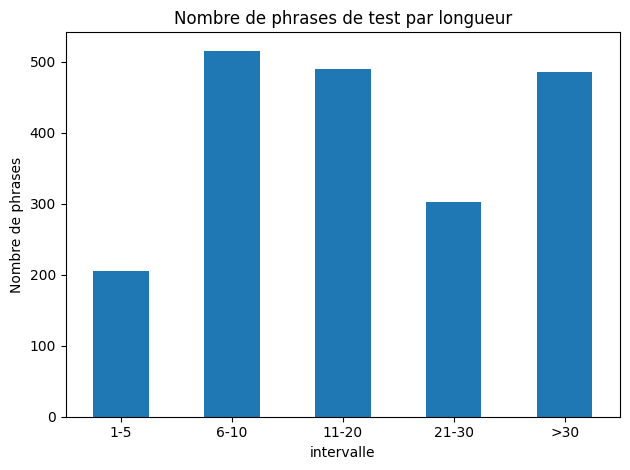

In [8]:
def length_bucket(n):
    if n <= 5: return "1-5"
    if n <= 10: return "6-10"
    if n <= 20: return "11-20"
    if n <= 30: return "21-30"
    return ">30"

summary = []
for name, rows in [("train", train_rows), ("validation", validation_rows), ("test", test_rows)]:
    src_lengths = [len(r["src_tokens"]) for r in rows]
    tgt_lengths = [len(r["tgt_tokens"]) for r in rows]
    summary.append({"split": name, "pairs": len(rows),
                    "mean_src_tokens": np.mean(src_lengths), "max_src_tokens": max(src_lengths),
                    "mean_tgt_tokens": np.mean(tgt_lengths), "max_tgt_tokens": max(tgt_lengths)})
display(pd.DataFrame(summary))

bucket_order = ["1-5", "6-10", "11-20", "21-30", ">30"]
test_buckets = Counter(length_bucket(len(r["src_tokens"])) for r in test_rows)
bucket_table = pd.DataFrame({"intervalle": bucket_order,
                             "nombre_test": [test_buckets[b] for b in bucket_order]})
display(bucket_table)
bucket_table.plot.bar(x="intervalle", y="nombre_test", legend=False,
                      title="Nombre de phrases de test par longueur", rot=0)
plt.ylabel("Nombre de phrases")
plt.tight_layout()
plt.show()


## 7. Construire les vocabulaires sur l'entraînement seulement
On conserve les tokens présents au moins deux fois, puis les plus fréquents jusqu'à la limite. Le tri alphabétique départage les fréquences égales pour obtenir un ordre déterministe. Les tokens non retenus deviennent `<UNK>` ; mesurer leur taux à la cellule suivante.


In [9]:
def build_vocab(rows, token_field, max_size, min_frequency):
    counts = Counter(token for row in rows for token in row[token_field])
    vocab = {"<PAD>": 0, "<UNK>": 1, "<SOS>": 2, "<EOS>": 3}
    ranked = sorted(counts.items(), key=lambda item: (-item[1], item[0]))
    for token, count in ranked:
        if count < min_frequency:
            break
        if len(vocab) >= max_size:
            break
        if token not in vocab:
            vocab[token] = len(vocab)
    return vocab


In [10]:
vocab_fr = build_vocab(train_rows, "src_tokens", CONFIG["max_vocab_size"], CONFIG["min_frequency"])
vocab_en = build_vocab(train_rows, "tgt_tokens", CONFIG["max_vocab_size"], CONFIG["min_frequency"])
CONFIG["source_vocab_size"] = len(vocab_fr)
CONFIG["target_vocab_size"] = len(vocab_en)
print("Taille vocabulaire FR :", len(vocab_fr))
print("Taille vocabulaire EN :", len(vocab_en))
print("Premiers tokens FR :", list(vocab_fr.items())[:15])
assert all(vocab_fr[token] == idx and vocab_en[token] == idx
           for token, idx in CONFIG["special_tokens"].items())
assert sorted(vocab_fr.values()) == list(range(len(vocab_fr)))
assert sorted(vocab_en.values()) == list(range(len(vocab_en)))


Taille vocabulaire FR : 10000
Taille vocabulaire EN : 10000
Premiers tokens FR : [('<PAD>', 0), ('<UNK>', 1), ('<SOS>', 2), ('<EOS>', 3), ('.', 4), ('de', 5), (',', 6), ('la', 7), ('et', 8), ('le', 9), ('des', 10), ('les', 11), ('à', 12), ('-', 13), ('du', 14)]


## 8. Convertir en indices et mesurer les tokens inconnus
Source : tokens + `<EOS>`. Cible : `<SOS>` + tokens + `<EOS>`. La longueur source réelle inclut `<EOS>`, mais `src_token_count` n'inclut aucun token spécial.
La reconstruction peut afficher `<UNK>` : c'est normal si un token a été exclu du vocabulaire.


In [11]:
def encode_row(row, vocab_fr, vocab_en):
    item = dict(row)
    item["src_ids"] = [vocab_fr.get(t, UNK_ID) for t in row["src_tokens"]] + [EOS_ID]
    item["tgt_ids"] = [SOS_ID] + [vocab_en.get(t, UNK_ID) for t in row["tgt_tokens"]] + [EOS_ID]
    item["src_token_count"] = len(row["src_tokens"])
    item["src_length"] = len(item["src_ids"])
    return item

def decode_ids(ids, vocab, remove_special=True):
    reverse = {idx: token for token, idx in vocab.items()}
    skipped = {PAD_ID, SOS_ID, EOS_ID} if remove_special else set()
    return [reverse.get(int(idx), "<UNK>") for idx in ids if int(idx) not in skipped]


In [12]:
prepared = {
    "train": [encode_row(r, vocab_fr, vocab_en) for r in train_rows],
    "validation": [encode_row(r, vocab_fr, vocab_en) for r in validation_rows],
    "test": [encode_row(r, vocab_fr, vocab_en) for r in test_rows],
}
example = prepared["train"][0]
print("FR :", example["fr"])
print("Indices source :", example["src_ids"])
print("Reconstruction :", decode_ids(example["src_ids"], vocab_fr))
print("EN :", example["en"])
print("Indices cible :", example["tgt_ids"])

coverage = []
for split, rows in prepared.items():
    for language, field in [("fr", "src_ids"), ("en", "tgt_ids")]:
        ids = [i for row in rows for i in row[field] if i not in {PAD_ID, SOS_ID, EOS_ID}]
        coverage.append({"split": split, "language": language,
                         "unknown_percent": 100 * ids.count(UNK_ID) / max(1, len(ids))})
display(pd.DataFrame(coverage))


FR : pourquoi les étoiles ne tombent pas du ciel
Indices source : [266, 11, 4957, 37, 1, 26, 14, 2384, 3]
Reconstruction : ['pourquoi', 'les', 'étoiles', 'ne', '<UNK>', 'pas', 'du', 'ciel']
EN : why don't the stars fall from the sky
Indices cible : [2, 225, 83, 5, 5280, 1314, 34, 5, 3770, 3]


,split,language,unknown_percent
0,train,fr,7.523948
1,train,en,5.154455
2,validation,fr,9.051536
3,validation,en,6.480654
4,test,fr,8.857382
5,test,en,7.014120


## 9. Dataset et batchs avec padding
`decoder_input` contient `<SOS>` puis les tokens précédents. `target` contient les tokens attendus puis `<EOS>`. On décale chaque phrase AVANT de padder.

Le masque source vaut **True aux positions valides**, y compris `<EOS>`. Pour l'attention : `scores.masked_fill(~src_mask, -inf)` avant le softmax. Les longueurs restent sur CPU pour `pack_padded_sequence(..., batch_first=True, enforce_sorted=False)` dans l'encodeur.


In [13]:
class TranslationDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, index):
        return self.rows[index]

def collate_translation(rows):
    src_sequences = [torch.tensor(r["src_ids"], dtype=torch.long) for r in rows]
    input_sequences = [torch.tensor(r["tgt_ids"][:-1], dtype=torch.long) for r in rows]
    target_sequences = [torch.tensor(r["tgt_ids"][1:], dtype=torch.long) for r in rows]
    src = pad_sequence(src_sequences, batch_first=True, padding_value=PAD_ID)
    decoder_input = pad_sequence(input_sequences, batch_first=True, padding_value=PAD_ID)
    target = pad_sequence(target_sequences, batch_first=True, padding_value=PAD_ID)
    return {
        "src": src,
        "src_lengths": torch.tensor([len(s) for s in src_sequences], dtype=torch.long),
        "src_token_counts": torch.tensor([r["src_token_count"] for r in rows], dtype=torch.long),
        "src_mask": src.ne(PAD_ID),
        "decoder_input": decoder_input,
        "target": target,
        "target_mask": target.ne(PAD_ID),
        "source_texts": [r["fr"] for r in rows],
        "reference_texts": [r["en"] for r in rows],
    }

def make_loaders(prepared, config):
    generator = torch.Generator().manual_seed(config["seed"])
    return {
        name: DataLoader(TranslationDataset(rows), batch_size=config["batch_size"],
                         shuffle=(name == "train"), collate_fn=collate_translation,
                         num_workers=0, generator=generator if name == "train" else None)
        for name, rows in prepared.items()
    }


In [14]:
loaders = make_loaders(prepared, CONFIG)
train_loader = loaders["train"]
validation_loader = loaders["validation"]
test_loader = loaders["test"]
batch = next(iter(train_loader))
for key in ["src", "src_lengths", "src_mask", "decoder_input", "target"]:
    print(key, tuple(batch[key].shape))
print("Source du premier exemple :", batch["source_texts"][0])
print("Référence :", batch["reference_texts"][0])
print("Longueurs réelles :", batch["src_lengths"][:5].tolist())
assert batch["decoder_input"].shape == batch["target"].shape
assert torch.all(batch["decoder_input"][:, 0] == SOS_ID)
assert torch.equal(batch["src_mask"].sum(dim=1), batch["src_lengths"])
for i, length in enumerate(batch["src_lengths"].tolist()):
    assert batch["src"][i, length - 1].item() == EOS_ID


src (64, 58)
src_lengths (64,)
src_mask (64, 58)
decoder_input (64, 60)
target (64, 60)
Source du premier exemple : oui, il ne va me donner aucun argent jusqu'à ce que je sois marié, et je ne me marierai jamais.
Référence : yeah, he's not gonna give me any money until i'm married, and i'm never gonna get married.
Longueurs réelles : [24, 10, 16, 38, 11]


## 10. Vérifier la loss et le décalage
Les logits ci-dessous sont ALÉATOIRES et servent seulement à vérifier la forme attendue et l'ignorance du padding. Ce n'est pas une performance de modèle. Une petite taille de vocabulaire fictive évite d'allouer un grand tenseur pour ce contrôle.
Pour vos modèles, la forme des logits sera `[batch_size, longueur_cible, taille_vocabulaire_EN]`.


In [15]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

# Contrôle avec deux phrases fictives de longueurs différentes.
toy_rows = [
    {"src_ids": [4, 5, EOS_ID], "tgt_ids": [SOS_ID, 6, EOS_ID],
     "src_token_count": 2, "fr": "exemple long", "en": "example"},
    {"src_ids": [7, EOS_ID], "tgt_ids": [SOS_ID, 4, 5, EOS_ID],
     "src_token_count": 1, "fr": "court", "en": "short phrase"},
]
toy = collate_translation(toy_rows)
assert toy["decoder_input"][0].tolist() == [SOS_ID, 6, PAD_ID]
assert toy["target"][0].tolist() == [6, EOS_ID, PAD_ID]

logits = torch.randn(2, 3, 8)  # pas un modèle entraîné
flat_logits = logits.reshape(-1, 8)
flat_target = toy["target"].reshape(-1)
loss = criterion(flat_logits, flat_target)
valid = flat_target.ne(PAD_ID)
loss_without_padding = nn.functional.cross_entropy(flat_logits[valid], flat_target[valid])
assert torch.allclose(loss, loss_without_padding)
print("Padding et décalage vérifiés. Loss fictive :", loss.item())

# Dans la boucle d'entraînement :
# loss = criterion(logits.reshape(-1, len(vocab_en)), batch['target'].reshape(-1))
# Pour une loss d'époque comparable, agréger la somme des pertes / nombre de tokens valides.


Padding et décalage vérifiés. Loss fictive : 3.1498637199401855


## 11. Sauvegarder les ensembles, vocabulaires et réglages
Les fichiers JSONL contiennent textes, tokens et indices. La sauvegarde du professeur, si utilisée, reste intacte : on écrit dans un dossier distinct. Les versions des bibliothèques et les empreintes SHA-256 permettent de vérifier la base partagée.


In [16]:
def write_json(path, data):
    Path(path).write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")

def write_jsonl(path, rows):
    with Path(path).open("w", encoding="utf-8") as f:
        for row in rows:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")

for split, rows in prepared.items():
    write_jsonl(DATA_DIR / f"{split}.jsonl", rows)
write_json(DATA_DIR / "vocab_fr.json", vocab_fr)
write_json(DATA_DIR / "vocab_en.json", vocab_en)
write_json(PROJECT_DIR / "config.json", CONFIG)
write_json(DATA_DIR / "split_audit.json", split_audit)
pd.DataFrame(coverage).to_csv(DATA_DIR / "unknown_token_rates.csv", index=False)
bucket_table.to_csv(DATA_DIR / "test_length_groups.csv", index=False)

versions = {name: importlib.metadata.version(name)
            for name in ["torch", "datasets", "pandas", "numpy", "matplotlib"]}
versions["python"] = platform.python_version()
write_json(PROJECT_DIR / "environment_versions.json", versions)
requirements = "\n".join(f"{name}=={version}" for name, version in versions.items() if name != "python")
(PROJECT_DIR / "requirements.txt").write_text(requirements + "\n", encoding="utf-8")
print("Fichiers préparés dans :", DATA_DIR.resolve())


Fichiers préparés dans : /content/nlp_translation/data/prepared


## 12. Générer `src/data.py` pour les autres notebooks
Le module contient le même nettoyage, le Dataset, le collate et les fonctions de rechargement. Il ne télécharge pas le corpus et ne reconstruit pas les vocabulaires.
Le code exporté est inclus explicitement ci-dessous pour rester autonome.


In [17]:
MODULE_SOURCE = r'''
"""Préparation commune : importable sans téléchargement ni entraînement."""
import json
import re
import unicodedata
from pathlib import Path
import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
PAD_ID, UNK_ID, SOS_ID, EOS_ID = 0, 1, 2, 3
TOKEN_PATTERN = re.compile(r"[^\W\d_]+(?:'[^\W\d_]+)*|\d+|[^\w\s]", flags=re.UNICODE)

def clean_text(text, lowercase=True):
    if not isinstance(text, str):
        raise TypeError("Une phrase doit être une chaîne de caractères.")
    text = unicodedata.normalize("NFKC", text)
    text = text.replace("’", "'")
    text = " ".join(text.split())
    return text.lower() if lowercase else text

def tokenize(text, lowercase=True):
    return TOKEN_PATTERN.findall(clean_text(text, lowercase=lowercase))

def prepare_pair(fr, en, lowercase=True):
    fr_clean = clean_text(fr, lowercase)
    en_clean = clean_text(en, lowercase)
    return {
        "fr_original": fr,
        "en_original": en,
        "fr": fr_clean,
        "en": en_clean,
        "src_tokens": tokenize(fr_clean, lowercase),
        "tgt_tokens": tokenize(en_clean, lowercase),
    }

def pair_key(row):
    return (tuple(row["src_tokens"]), tuple(row["tgt_tokens"]))

def encode_row(row, vocab_fr, vocab_en):
    item = dict(row)
    item["src_ids"] = [vocab_fr.get(t, UNK_ID) for t in row["src_tokens"]] + [EOS_ID]
    item["tgt_ids"] = [SOS_ID] + [vocab_en.get(t, UNK_ID) for t in row["tgt_tokens"]] + [EOS_ID]
    item["src_token_count"] = len(row["src_tokens"])
    item["src_length"] = len(item["src_ids"])
    return item

def decode_ids(ids, vocab, remove_special=True):
    reverse = {idx: token for token, idx in vocab.items()}
    skipped = {PAD_ID, SOS_ID, EOS_ID} if remove_special else set()
    return [reverse.get(int(idx), "<UNK>") for idx in ids if int(idx) not in skipped]

class TranslationDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, index):
        return self.rows[index]

def collate_translation(rows):
    src_sequences = [torch.tensor(r["src_ids"], dtype=torch.long) for r in rows]
    input_sequences = [torch.tensor(r["tgt_ids"][:-1], dtype=torch.long) for r in rows]
    target_sequences = [torch.tensor(r["tgt_ids"][1:], dtype=torch.long) for r in rows]
    src = pad_sequence(src_sequences, batch_first=True, padding_value=PAD_ID)
    decoder_input = pad_sequence(input_sequences, batch_first=True, padding_value=PAD_ID)
    target = pad_sequence(target_sequences, batch_first=True, padding_value=PAD_ID)
    return {
        "src": src,
        "src_lengths": torch.tensor([len(s) for s in src_sequences], dtype=torch.long),
        "src_token_counts": torch.tensor([r["src_token_count"] for r in rows], dtype=torch.long),
        "src_mask": src.ne(PAD_ID),
        "decoder_input": decoder_input,
        "target": target,
        "target_mask": target.ne(PAD_ID),
        "source_texts": [r["fr"] for r in rows],
        "reference_texts": [r["en"] for r in rows],
    }

def make_loaders(prepared, config):
    generator = torch.Generator().manual_seed(config["seed"])
    return {
        name: DataLoader(TranslationDataset(rows), batch_size=config["batch_size"],
                         shuffle=(name == "train"), collate_fn=collate_translation,
                         num_workers=0, generator=generator if name == "train" else None)
        for name, rows in prepared.items()
    }

def load_prepared(project_dir):
    project_dir = Path(project_dir)
    data_dir = project_dir / "data" / "prepared"
    def load_json(path):
        return json.loads(Path(path).read_text(encoding="utf-8"))
    config = load_json(project_dir / "config.json")
    vocab_fr = load_json(data_dir / "vocab_fr.json")
    vocab_en = load_json(data_dir / "vocab_en.json")
    prepared = {}
    for name in ["train", "validation", "test"]:
        with (data_dir / f"{name}.jsonl").open(encoding="utf-8") as f:
            prepared[name] = [json.loads(line) for line in f if line.strip()]
    return config, vocab_fr, vocab_en, prepared

def encode_source(text, vocab_fr, lowercase=True):
    tokens = tokenize(text, lowercase)
    return [vocab_fr.get(token, UNK_ID) for token in tokens] + [EOS_ID]
'''
(SRC_DIR / "data.py").write_text(MODULE_SOURCE, encoding="utf-8")
(SRC_DIR / "__init__.py").write_text("", encoding="utf-8")
print("Module créé :", SRC_DIR / "data.py")


Module créé : nlp_translation/src/data.py


## 13. Recharger et vérifier la sauvegarde
Ce contrôle compare les données rechargées aux données en mémoire, sans les recalculer.


In [18]:
import sys
if str(PROJECT_DIR.resolve()) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR.resolve()))
from src.data import load_prepared
loaded_config, loaded_fr, loaded_en, loaded_rows = load_prepared(PROJECT_DIR)
assert loaded_config == CONFIG
assert loaded_fr == vocab_fr and loaded_en == vocab_en
assert loaded_rows == prepared
print("Rechargement vérifié : mêmes réglages, vocabulaires, textes et indices.")

files_to_hash = [p for p in PROJECT_DIR.rglob("*")
                 if p.is_file() and p.suffix in {".json", ".jsonl", ".csv", ".py", ".txt"}
                 and "__pycache__" not in p.parts and p.name != "manifest.json"]
manifest = {str(p.relative_to(PROJECT_DIR)): hashlib.sha256(p.read_bytes()).hexdigest()
            for p in sorted(files_to_hash)}
write_json(PROJECT_DIR / "manifest.json", manifest)
print("Empreintes enregistrées dans manifest.json.")


Rechargement vérifié : mêmes réglages, vocabulaires, textes et indices.
Empreintes enregistrées dans manifest.json.


## 14. Créer l'archive à partager
Sur Colab, exécuter la ligne `files.download` pour télécharger le ZIP. Partager la même archive au binôme. Le téléchargement du notebook lui-même se fait avec **Fichier → Télécharger → Télécharger le fichier .ipynb**.
Pour GitHub : ajouter le notebook, `src/data.py`, `config.json` et `requirements.txt`. Les données peuvent être conservées dans le dossier Drive commun.


In [19]:
archive_path = shutil.make_archive(str(PROJECT_DIR.resolve()) + "_base_commune", "zip",
                                   root_dir=PROJECT_DIR.parent, base_dir=PROJECT_DIR.name)
print("Archive créée :", archive_path)
# Google Colab uniquement : décommenter les deux lignes suivantes.
from google.colab import files
files.download(archive_path)


Archive créée : /content/nlp_translation_base_commune.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Code de rechargement pour le binôme et les modèles
Après avoir extrait l'archive dans le dossier courant, exécuter cette cellule dans le notebook d'entraînement. Ne pas relancer le téléchargement ni reconstruire les vocabulaires.

Pour un nouveau run de modèle, reconstruire les loaders afin de repartir du même ordre aléatoire d'entraînement. Au test : `model.eval()`, `torch.no_grad()` et génération depuis `<SOS>` avec les prédictions du modèle. Les références servent au score, pas à la génération.


In [20]:
from pathlib import Path
import sys
import torch

project_dir = Path("nlp_translation").resolve()
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))
from src.data import load_prepared, make_loaders, encode_source

config, vocab_fr, vocab_en, prepared_rows = load_prepared(project_dir)
shared_loaders = make_loaders(prepared_rows, config)
print("Taille entraînement :", len(prepared_rows["train"]))
print("Vocabulaire FR / EN :", len(vocab_fr), len(vocab_en))
print("Exemple :", prepared_rows["train"][0]["src_ids"])
new_sentence_ids = encode_source("Je cherche un stage.", vocab_fr, config["lowercase"])
print("Nouvelle phrase encodée :", new_sentence_ids)

# À intégrer ensuite dans la boucle du modèle :
# batch = next(iter(shared_loaders['train']))
# src = batch['src'].to(device)
# lengths = batch['src_lengths']  # garder sur CPU pour pack_padded_sequence
# decoder_input = batch['decoder_input'].to(device)
# target = batch['target'].to(device)
# source_mask = batch['src_mask'].to(device)


Taille entraînement : 30000
Vocabulaire FR / EN : 10000 10000
Exemple : [266, 11, 4957, 37, 1, 26, 14, 2384, 3]
Nouvelle phrase encodée : [29, 2152, 20, 8599, 4, 3]


## Fin : liste de vérification
- [ ] 30 000 / 2 000 / 2 000 paires et direction FR → EN.
- [ ] Aucun recouvrement exact train/validation ou train/test après tokenisation.
- [ ] Vocabulaires construits uniquement sur l'entraînement.
- [ ] Mêmes identifiants spéciaux et réglages pour les quatre modèles.
- [ ] Batchs, décalage des cibles et loss sans padding vérifiés.
- [ ] Phrases longues conservées et nombres par groupe enregistrés.
- [ ] Même archive rechargée par les deux personnes.

Ce notebook ne calcule pas encore BLEU et n'entraîne pas de modèle. Prochaine étape : LSTM sans attention et boucle d'entraînement.
